# M1 extension - MobileNetV2 with an "others" class (21 classes)

The M1 classifier is closed-set: it always returns one of the 20 course IDs, even for an object that is not one of them.
Here a 21st class, `OTHERS`, is added: about 100 photos of everyday objects that are **not** any of the 20 course objects.
The model then has a way to answer "not one of the 20 objects".

Only MobileNetV2 (the model selected in M1) is retrained, with the same recipe as M1. The M1 four-model comparison is unchanged.

| Task | Content |
|---|---|
| 1 | Configuration and paths |
| 2 | Load the M1 split (`split_manifest.csv`, `classes.json`) unchanged and copy the 20-class images |
| 3 | Import the `OTHERS` photos and the unseen-object photos: square crop, checks, near-duplicate groups, split |
| 4 | Data pipeline and augmentation (same as M1) |
| 5 | MobileNetV2 with 21 outputs, trained in two stages (same as M1) |
| 6 | Results on **validation only**, saved before any test evaluation |
| 7 | Test: the 303 M1 test images, the `OTHERS` test images, and the unseen-object photos |
| 8 | Saved model, class map and run records |

## Photos to prepare

| Folder | What goes in | Used for |
|---|---|---|
| `others/images_OTHERS/` | ~100 photos of everyday objects that are not any of the 20 course objects; one object per photo, 20+ different kinds, varied backgrounds | training / validation / test (70 / 15 / 15 by group) |
| `others/unseen_test/` | 30–50 photos of object **kinds that are not in `images_OTHERS`** (e.g. no shoes in `images_OTHERS` → shoes here) | evaluation only, never trained on |

Put the object near the center: every photo is cropped to the central square and resized to 224×224, like the course images.
HEIC (iPhone), JPG and PNG all work.

**Colab:** on the laptop run `python classification/src/make_cache_zips.py` (after the photos are in place). It writes two zips to
`detection/cluster/IE7615_project/cache/`; upload both to `MyDrive/data/IE7615_project/cache/` (not into the shared course folder),
then choose a T4 GPU and run all. Each zip is one file to read from Drive instead of thousands of small files:
- `course_images_m1.zip`: the 2,022 course images (without it, the first run reads the shared folder and writes this zip itself)
- `others.zip`: `images_OTHERS/` and `unseen_test/` (a `cache/others/` folder works too; the folder wins if both exist)
**Laptop:** the defaults point to the local copies in this repository (`detection/cluster/data/raw`, `classification/others`).

# Task1 - Configuration and paths

In [1]:
import os, sys, json, time, uuid, hashlib, shutil, platform, re, csv, subprocess, math, zipfile
from pathlib import Path
from datetime import datetime, timezone

IN_COLAB = "google.colab" in sys.modules
SMOKE = os.environ.get("M1O_SMOKE") == "1"     # smoke test: few images, 1 epoch, no pretrained weights
if IN_COLAB:
    # iPhone photos are HEIC; Pillow needs the pillow-heif plugin to open them
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pillow-heif"], check=False)

import numpy as np
from PIL import Image, ImageOps
try:
    import pillow_heif
    pillow_heif.register_heif_opener()
    HEIF_OK = True
except ImportError:
    HEIF_OK = False

import matplotlib
if not IN_COLAB:
    matplotlib.use("Agg")      # no screen when run from the command line
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import tensorflow as tf
import keras
from keras import layers
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPU:", tf.config.list_physical_devices("GPU"), "| HEIC support:", HEIF_OK)

TensorFlow 2.21.0 | Keras 3.13.2 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | HEIC support: True


In [2]:
# Same settings as the M1 MobileNetV2 run, so the only change is the extra class
SEED = 42
SPLIT_RATIOS = (0.70, 0.15, 0.15)   # train / val / test, used for the OTHERS photos (the 20 classes keep the M1 split)
IMG_SIZE = 224
BATCH = 32
PHASH_THRESHOLD = 4                 # near-duplicate: pHash Hamming distance <= 4 (as in M1)
WEIGHT_DECAY = 1e-4
PRETRAINED = None if SMOKE else "imagenet"
EPOCHS = dict(head=10, finetune=20)
PATIENCE = dict(finetune=5)
LR = dict(head=1e-3, finetune=1e-4)
UNFREEZE_FROM = "block_13_expand"   # MobileNetV2 blocks unfrozen in stage 2 (as in M1)
OTHERS_ID = "OTHERS"
MIN_OTHERS = 60                     # fewer usable OTHERS photos → stop: too few to train and evaluate the class
M1_MOBILENET = dict(val_accuracy=0.9967, test_accuracy=0.9934)   # 20-class MobileNetV2 in the M1 run, for comparison
MAX_PER_SPLIT = None
if SMOKE:
    EPOCHS = dict(head=1, finetune=1)
    MAX_PER_SPLIT = 3               # per class and split
    MIN_OTHERS = 5

In [3]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/data/student uploaded files")   # shared course folder (read only)
    PROJECT = Path("/content/drive/MyDrive/data/IE7615_project")            # M1 run and outputs
    OTHERS_ROOT = PROJECT / "cache" / "others"                               # your own photos (next to course_images_m1.zip)
    WORK_DIR = Path("/content/m1o_data")
else:
    # Repository root = first folder upwards that contains detection/ (works from the repo root or from classification/)
    ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "detection").is_dir()), Path.cwd())
    DATA_DIR = Path(os.environ.get("M1O_DATA_DIR", ROOT / "detection" / "cluster" / "data" / "raw"))
    PROJECT = Path(os.environ.get("M1O_PROJECT", ROOT / "detection" / "cluster" / "IE7615_project"))
    OTHERS_ROOT = Path(os.environ.get("M1O_OTHERS_ROOT", ROOT / "classification" / "others"))
    WORK_DIR = Path(os.environ.get("M1O_WORK_DIR", ROOT / "m1o_data"))
M1_RUN_DIR = Path(os.environ.get("M1O_M1_RUN", PROJECT / "runs" / "m1_20261018_022316"))   # the submitted M1 run
OTHERS_ZIP = PROJECT / "cache" / "others.zip"   # images_OTHERS/ and unseen_test/ in one file (made by src/make_cache_zips.py)

for p, what in [(DATA_DIR, "course data folder"), (M1_RUN_DIR, "M1 run folder")]:
    if not p.exists():
        raise FileNotFoundError(f"{what} not found: {p}")

RUN_TAG = datetime.now().strftime("m1o_%Y%m%d_%H%M%S") + ("_smoke" if SMOKE else "")
OUT_DIR = PROJECT / "runs" / RUN_TAG
for sub in ["data", "models", "figures", "records"]:
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)
if WORK_DIR.exists():
    shutil.rmtree(WORK_DIR)
WORK_DIR.mkdir(parents=True)

# The photo folder is used when it exists; otherwise others.zip is unzipped (one file to read from Drive)
if (OTHERS_ROOT / "images_OTHERS").is_dir():
    OTHERS_FROM = "folder"
elif OTHERS_ZIP.exists():
    with zipfile.ZipFile(OTHERS_ZIP) as zf:
        zf.extractall(WORK_DIR / "_others")
    OTHERS_ROOT = WORK_DIR / "_others"
    if (OTHERS_ROOT / "others" / "images_OTHERS").is_dir():   # zip made from the parent folder
        OTHERS_ROOT = OTHERS_ROOT / "others"
    OTHERS_FROM = f"zip {OTHERS_ZIP.name}"
else:
    raise FileNotFoundError(f"OTHERS photos not found: neither {OTHERS_ROOT / 'images_OTHERS'} nor {OTHERS_ZIP}")
OTHERS_DIR = OTHERS_ROOT / "images_OTHERS"
UNSEEN_DIR = OTHERS_ROOT / "unseen_test"
print("M1 run:       ", M1_RUN_DIR)
print("OTHERS photos:", OTHERS_DIR, f"(from the {OTHERS_FROM})")
print("Output folder:", OUT_DIR)

Mounted at /content/drive
M1 run:        /content/drive/MyDrive/data/IE7615_project/runs/m1_20261018_022316
OTHERS photos: /content/m1o_data/_others/images_OTHERS (from the zip others.zip)
Output folder: /content/drive/MyDrive/data/IE7615_project/runs/m1o_20261107_113839


# Task2 - Load the M1 split and copy the 20-class images
The 20 course classes keep the M1 split **unchanged** (checksums compared with the M1 run), and every file is checked against the md5 recorded in M1.
So the 303 test images are exactly the M1 test images, and the result can be compared with the 20-class model.
The images come from `IE7615_project/cache/course_images_m1.zip` when it exists (seconds), otherwise from the shared folder (minutes; the zip is then written).

In [4]:
issues = []                                    # every data problem the report should mention

def file_hash(path, algo="sha256"):
    h = hashlib.new(algo)
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def md_table(header, rows):
    lines = ["| " + " | ".join(map(str, header)) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(map(str, r)) + " |" for r in rows]
    return "\n".join(lines)

classes_path = M1_RUN_DIR / "data" / "classes.json"
manifest_path = M1_RUN_DIR / "data" / "split_manifest.csv"
CLASSES_SHA, MANIFEST_SHA = file_hash(classes_path), file_hash(manifest_path)
EXPECTED = dict(classes="511d30a1", manifest="ce9172b7")      # recorded in the M1 run
if not SMOKE and not (CLASSES_SHA.startswith(EXPECTED["classes"]) and MANIFEST_SHA.startswith(EXPECTED["manifest"])):
    raise RuntimeError("classes.json or split_manifest.csv differs from the M1 run; the 20 classes must keep the M1 split.")

CLASSES20 = {int(k): v for k, v in json.loads(classes_path.read_text(encoding="utf-8")).items()}
OTHERS_IDX = len(CLASSES20)                     # 20: the new class comes after the 20 course classes, so 0–19 keep their M1 meaning
CLASSES = {**CLASSES20, OTHERS_IDX: OTHERS_ID}
NUM_CLASSES = len(CLASSES)
SPLITS = ["train", "val", "test"]

# Reading 2,022 small files one by one from Drive is slow. All course images are therefore kept in one zip on Drive:
# one file to read instead of 2,022. If the zip is missing, the images are read from the shared folder once and the zip is
# written for the next run. Either way every image is checked against the md5 recorded in M1.
CACHE_ZIP = PROJECT / "cache" / "course_images_m1.zip"
def norm(src_path):
    folder, name = src_path.split("/", 1)
    return f"{folder.strip()}/{name}"          # folder names may carry trailing spaces (e.g. 'images_OBJ001 ')

t0 = time.time()
if CACHE_ZIP.exists():
    with zipfile.ZipFile(CACHE_ZIP) as zf:
        zf.extractall(WORK_DIR / "_course")
    SRC_ROOT, FROM_CACHE = WORK_DIR / "_course", True
else:
    SRC_ROOT, FROM_CACHE = DATA_DIR, False
folders = {p.name.strip(): p for p in SRC_ROOT.iterdir() if p.is_dir()}
with open(manifest_path, newline="", encoding="utf-8") as f:
    sources = list(csv.DictReader(f))

records, taken, n_bad = [], {}, 0
for r in sources:
    key = (r["class_id"], r["split"])
    if MAX_PER_SPLIT and taken.get(key, 0) >= MAX_PER_SPLIT:
        continue
    folder, name = norm(r["src_path"]).split("/", 1)
    src = folders.get(folder, SRC_ROOT / folder) / name
    dst = WORK_DIR / r["class_id"] / Path(r["local_path"]).name
    dst.parent.mkdir(parents=True, exist_ok=True)
    if not src.exists():
        issues.append(f"missing source file, skipped: {r['src_path']}"); n_bad += 1
        continue
    shutil.copy2(src, dst)                     # one read from the source; the md5 is computed on the local copy
    if file_hash(dst, "md5") != r["md5"]:
        issues.append(f"source file differs from M1 (md5), skipped: {r['src_path']}"); n_bad += 1
        dst.unlink()
        continue
    records.append(dict(image_id=r["image_id"], class_id=r["class_id"], class_idx=int(r["class_idx"]), split=r["split"],
                        group_id=r["group_id"], src_path=norm(r["src_path"]), path=str(dst)))
    taken[key] = taken.get(key, 0) + 1
print(f"20 course classes: {len(records)} images from {'the cache ' + CACHE_ZIP.name if FROM_CACHE else 'the shared folder'} "
      f"in {time.time() - t0:.0f} s ({', '.join(f'{s} {sum(x['split'] == s for x in records)}' for s in SPLITS)}); "
      f"classes.json {CLASSES_SHA[:8]}…, split_manifest.csv {MANIFEST_SHA[:8]}…")

# First full run without the cache: write it, so the next run reads one file
if not FROM_CACHE and not SMOKE and n_bad == 0 and len(records) == len(sources):
    CACHE_ZIP.parent.mkdir(parents=True, exist_ok=True)
    tmp = WORK_DIR / CACHE_ZIP.name
    with zipfile.ZipFile(tmp, "w", zipfile.ZIP_STORED) as zf:     # JPEGs are already compressed
        for r in records:
            zf.write(r["path"], arcname=r["src_path"])
    shutil.copy2(tmp, CACHE_ZIP)
    print(f"cache written: {CACHE_ZIP} ({CACHE_ZIP.stat().st_size / 1e6:.1f} MB)")
if issues:
    print("\n".join(" - " + s for s in issues))

20 course classes: 2022 images from the cache course_images_m1.zip in 5 s (train 1416, val 303, test 303); classes.json 511d30a1…, split_manifest.csv ce9172b7…


# Task3 - Import the OTHERS photos and the unseen-object photos
Every photo is turned upright (EXIF), cropped to the **central square** and resized to 224×224 JPEG, like the course images.
A square crop instead of padding matters: padded photos would carry black borders that only the OTHERS class has,
and the model could learn "black borders = OTHERS" instead of the objects (a shortcut).

In [5]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".heic", ".heif", ".tif", ".tiff"}

def load_square(path):
    """Upright RGB image, central square crop, resized to IMG_SIZE × IMG_SIZE."""
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
    s = min(im.size)
    left, top = (im.width - s) // 2, (im.height - s) // 2
    return im.crop((left, top, left + s, top + s)).resize((IMG_SIZE, IMG_SIZE), Image.Resampling.LANCZOS)

def kind_of(name):
    """Object kind from the file name: 'alarm_clock_03.jpg' → 'alarm_clock', 'empty_brick_wall.jpg' → 'empty',
    'keyboard (2).HEIC' (Windows batch rename) → 'keyboard'. An optional 'oth_' / 'uns_' prefix is ignored."""
    stem = Path(name).stem.lower().strip()
    stem = re.sub(r"\s*\(\d+\)$", "", stem)
    stem = re.sub(r"^(oth|uns)_", "", stem)
    if stem.startswith("empty"):
        return "empty"
    return re.sub(r"[_\-\s]*\d+$", "", stem) or stem

def import_folder(folder, prefix):
    files = sorted(f for f in folder.rglob("*") if f.is_file() and f.suffix.lower() in IMG_EXT and not f.name.startswith("."))
    out = []
    (WORK_DIR / prefix).mkdir(parents=True, exist_ok=True)
    for i, f in enumerate(files):
        if f.suffix.lower() in {".heic", ".heif"} and not HEIF_OK:
            issues.append(f"skipped HEIC (pillow-heif not installed): {f.name}")
            continue
        try:
            im = load_square(f)
        except Exception as e:
            issues.append(f"cannot read, skipped: {f.name} ({type(e).__name__})")
            continue
        image_id = f"{prefix}_{i:04d}"
        dst = WORK_DIR / prefix / f"{image_id}.jpg"
        im.save(dst, quality=95)
        out.append(dict(image_id=image_id, src_name=f.name, kind=kind_of(f.name), md5=file_hash(f, "md5"), path=str(dst)))
    return out

others = import_folder(OTHERS_DIR, OTHERS_ID)
unseen = import_folder(UNSEEN_DIR, "UNSEEN") if UNSEEN_DIR.is_dir() else []
if len(others) < MIN_OTHERS:
    raise RuntimeError(f"Only {len(others)} usable OTHERS photos (need at least {MIN_OTHERS}). Add photos to {OTHERS_DIR}.")
if not unseen:
    issues.append("no unseen-object photos: the test can only show how the model handles objects similar to the OTHERS photos")

# Kinds, from the file names
def kind_counts(rows):
    c = {}
    for r in rows:
        c[r["kind"]] = c.get(r["kind"], 0) + 1
    return dict(sorted(c.items()))
OTHERS_KINDS, UNSEEN_KINDS = kind_counts(others), kind_counts(unseen)
print(f"OTHERS: {len(others)} photos, {len(OTHERS_KINDS)} kinds: " + ", ".join(f"{k} {v}" for k, v in OTHERS_KINDS.items()))
print(f"UNSEEN: {len(unseen)} photos, {len(UNSEEN_KINDS)} kinds: " + ", ".join(f"{k} {v}" for k, v in UNSEEN_KINDS.items()))
overlap = sorted(set(OTHERS_KINDS) & set(UNSEEN_KINDS))
if overlap:
    issues.append(f"unseen kinds that also appear in OTHERS (not really unseen; rename or remove them): {overlap}")
if len(OTHERS_KINDS) < 20:
    issues.append(f"only {len(OTHERS_KINDS)} OTHERS kinds: the model may reject only objects similar to these kinds")

OTHERS: 100 photos, 31 kinds: alarm_clock 4, backpack 3, binoculars 3, butterfly 4, calculator 3, camera 4, chicken 3, computer_mouse 4, deer 4, empty 5, fire_hydrant 3, football 3, frog 3, guitar 3, houseplant 3, kite 3, laptop 3, microphone 3, mixing_bowl 3, mobile_phone 3, mushroom 3, pig 3, pillow 3, rabbit 3, remote_control 3, rose 3, scissors 3, spoon 3, traffic_light 3, umbrella 3, watch 3
UNSEEN: 36 photos, 18 kinds: candle 2, desk_lamp 2, dice 2, electric_kettle 2, glove 2, hat 2, headphones 2, pen 2, power_outlet 2, sock 2, stapler 2, sunglasses 2, tissue_box 2, toaster 2, toothbrush 2, towel 2, toy_car 2, wallet 2


In [6]:
# Exact duplicates (same file twice)
seen = {}
for r in others + unseen:
    if r["md5"] in seen:
        issues.append(f"identical files: {seen[r['md5']]} and {r['image_id']} ({r['src_name']})")
    seen.setdefault(r["md5"], r["image_id"])

# pHash (same as M1): near-duplicate groups inside OTHERS, and two cross-checks
def dct_matrix(n):
    k = np.arange(n)
    m = np.cos(np.pi * (2 * k[None, :] + 1) * k[:, None] / (2 * n)) * np.sqrt(2 / n)
    m[0] /= np.sqrt(2)
    return m

D32 = dct_matrix(32)

def phash_bits(path):
    with Image.open(path) as im:
        a = np.asarray(im.convert("L").resize((32, 32), Image.Resampling.LANCZOS), dtype=np.float64)
    low = (D32 @ a @ D32.T)[:8, :8]
    return (low > np.median(low)).flatten()

def packed(rows):
    return np.packbits(np.stack([phash_bits(r["path"]) for r in rows]), axis=1)

POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
def hamming(a, b):
    return POP[np.bitwise_xor(a[:, None, :], b[None, :, :])].sum(-1)

P_oth, P_cls = packed(others), packed(records)
for r, h in zip(others, P_oth):
    r["phash"] = h.tobytes().hex()

# 1) an OTHERS photo almost identical to a course image may show one of the 20 objects
for a, b in np.argwhere(hamming(P_oth, P_cls) <= PHASH_THRESHOLD):
    issues.append(f"OTHERS photo {others[a]['src_name']} looks like course image {records[b]['image_id']}: check it is not one of the 20 objects")
# 2) an unseen photo almost identical to an OTHERS photo is not really unseen
if unseen:
    P_uns = packed(unseen)
    for a, b in np.argwhere(hamming(P_uns, P_oth) <= PHASH_THRESHOLD):
        issues.append(f"unseen photo {unseen[a]['src_name']} is a near-duplicate of OTHERS photo {others[b]['src_name']}")

# Groups inside OTHERS (union-find on near-duplicate pairs), so a burst of shots stays in one split
parent = list(range(len(others)))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
H = hamming(P_oth, P_oth)
for a, b in np.argwhere(H <= PHASH_THRESHOLD):
    if a < b:
        parent[find(a)] = find(b)
groups = {}
for i in range(len(others)):
    groups.setdefault(find(i), []).append(i)

# Split by group, largest first, each group into the split furthest below its target (same rule as M1)
rng = np.random.default_rng([SEED, OTHERS_IDX])
order = rng.permutation(len(groups))
glist = sorted((list(groups.values())[k] for k in order), key=len, reverse=True)
n = len(others)
targets = [round(n * SPLIT_RATIOS[0]), round(n * SPLIT_RATIOS[1])]
targets.append(n - sum(targets))
counts = [0, 0, 0]
for gid, m in enumerate(glist):
    k = int(np.argmax([(targets[j] - counts[j]) / max(targets[j], 1) for j in range(3)]))
    counts[k] += len(m)
    for i in m:
        others[i].update(split=SPLITS[k], group_id=f"O{gid:04d}", group_size=len(m))
multi = [m for m in glist if len(m) > 1]
print(f"OTHERS: {len(glist)} groups ({len(multi)} with 2+ photos); split train / val / test = {counts[0]} / {counts[1]} / {counts[2]}")
for s in SPLITS:
    if not any(r["split"] == s for r in others):
        raise RuntimeError(f"no OTHERS photo in {s}; add more photos")

print("\nData issues:" if issues else "\nNo data issues.")
for s in issues:
    print(" -", s)

OTHERS: 100 groups (0 with 2+ photos); split train / val / test = 70 / 15 / 15

No data issues.


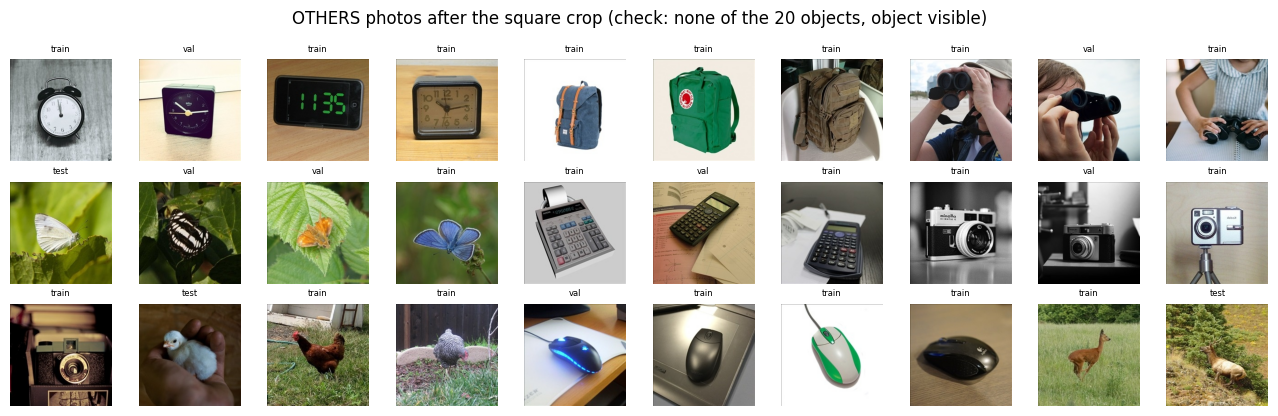

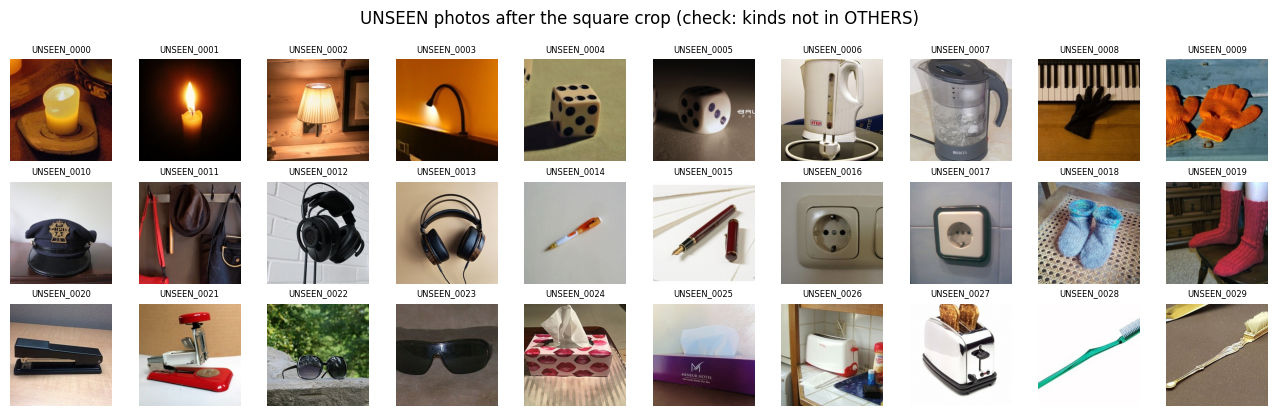

In [7]:
def sheet(rows, title, n=30, cols=10):
    rows = rows[:n]
    if not rows:
        return
    fig, axes = plt.subplots(math.ceil(len(rows) / cols), cols, figsize=(cols * 1.3, 1.4 * math.ceil(len(rows) / cols)), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, r in zip(axes.flat, rows):
        with Image.open(r["path"]) as im:
            ax.imshow(im)
        ax.set_title(r.get("split", r["image_id"]), fontsize=6)
    plt.suptitle(title); plt.tight_layout()
    plt.savefig(OUT_DIR / "figures" / f"{title.split()[0].lower()}_photos.jpg", dpi=90); plt.show()

sheet(others, "OTHERS photos after the square crop (check: none of the 20 objects, object visible)")
sheet(unseen, "UNSEEN photos after the square crop (check: kinds not in OTHERS)")

# Task4 - Data pipeline and augmentation (same as M1)

In [8]:
keras.utils.set_random_seed(SEED)
for r in others:
    r.update(class_id=OTHERS_ID, class_idx=OTHERS_IDX)
ALL = records + others

def items(split):
    rs = [r for r in ALL if r["split"] == split]
    return [r["path"] for r in rs], np.array([r["class_idx"] for r in rs]), rs

def decode(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize_with_pad(tf.cast(img, tf.float32), IMG_SIZE, IMG_SIZE)
    return tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8), tf.one_hot(label, NUM_CLASSES)

augment = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(15 / 360, fill_mode="reflect", seed=SEED),
    layers.RandomZoom(height_factor=(-0.2, 0.0), fill_mode="reflect", seed=SEED),
    layers.RandomTranslation(0.1, 0.1, fill_mode="reflect", seed=SEED),
    layers.RandomContrast(0.2, seed=SEED),
    layers.RandomBrightness(0.2, value_range=(0, 255), seed=SEED),
], name="augment")

def random_erase(img, p=0.5):
    def erase():
        eh = tf.random.uniform([], int(0.10 * IMG_SIZE), int(0.35 * IMG_SIZE), dtype=tf.int32)
        ew = tf.random.uniform([], int(0.10 * IMG_SIZE), int(0.35 * IMG_SIZE), dtype=tf.int32)
        y = tf.random.uniform([], 0, IMG_SIZE - eh, dtype=tf.int32)
        x = tf.random.uniform([], 0, IMG_SIZE - ew, dtype=tf.int32)
        mask = tf.pad(tf.ones([eh, ew, 1]), [[y, IMG_SIZE - y - eh], [x, IMG_SIZE - x - ew], [0, 0]])
        return img * (1 - mask) + tf.random.uniform([IMG_SIZE, IMG_SIZE, 3], 0, 255) * mask
    return tf.cond(tf.random.uniform([]) < p, erase, lambda: img)

def make_ds(paths, labels, training):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels)).map(decode, num_parallel_calls=tf.data.AUTOTUNE).cache()
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(lambda x, y: (random_erase(x), y), num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.batch(BATCH).map(lambda x, y: (tf.clip_by_value(augment(x, training=True), 0, 255), y),
                                 num_parallel_calls=tf.data.AUTOTUNE)
    else:
        ds = ds.batch(BATCH)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(*items("train")[:2], True)
val_ds = make_ds(*items("val")[:2], False)
test_ds = make_ds(*items("test")[:2], False)
unseen_ds = make_ds([r["path"] for r in unseen], np.full(len(unseen), OTHERS_IDX), False) if unseen else None
N_TRAIN = len(items("train")[0])
STEPS_PER_EPOCH = math.ceil(N_TRAIN / BATCH)
print(f"train / val / test images: {N_TRAIN} / {len(items('val')[0])} / {len(items('test')[0])} "
      f"(OTHERS {counts[0]} / {counts[1]} / {counts[2]}); unseen {len(unseen)}; steps per epoch = {STEPS_PER_EPOCH}")

train / val / test images: 1486 / 318 / 318 (OTHERS 70 / 15 / 15); unseen 36; steps per epoch = 47


# Task5 - MobileNetV2 with 21 outputs (same recipe as M1)
Stage 1 trains only the new head (backbone frozen); stage 2 unfreezes the top blocks with a 10× lower learning rate.
Early stopping on validation accuracy; if fine-tuning reaches lower validation accuracy than stage 1, the stage-1 weights are restored.

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
47/47 - 92s - 2s/step - accuracy: 0.4515 - loss: 2.0129 - val_accuracy: 0.8742 - val_loss: 0.6697
Epoch 2/10
47/47 - 82s - 2s/step - accuracy: 0.8466 - loss: 0.6530 - val_accuracy: 0.9088 - val_loss: 0.3523
Epoch 3/10
47/47 - 37s - 787ms/step - accuracy: 0.9152 - loss: 0.3831 - val_accuracy: 0.9371 - val_loss: 0.2449
Epoch 4/10
47/47 - 42s - 898ms/step - accuracy: 0.9307 - loss: 0.2968 - val_accuracy: 0.9371 - val_loss: 0.2076
Epoch 5/10
47/47 - 39s - 824ms/step - accuracy: 0.9495 - loss: 0.2247 - val_accuracy: 0.9560 - val_loss: 0.1746
Epoch 6/10
47/47 - 41s - 867ms/step - accuracy: 0.9536 - loss: 0.2216 - val_accuracy: 0.9528 - val_loss: 0.1684
Epoch 7/10
47/47 - 24s - 509ms/step - accuracy: 0.9630 - loss: 0.1928 - val_accuracy: 0.9528 - val_loss: 0.1598
Epoch 8/10
47/47 - 22s - 477ms/step - accuracy: 0.9630 - loss: 0.1889 - val_accuracy: 0.9560 - val_loss: 0.1555
Epoch 9/10
47/47 - 24s - 504ms/step - accuracy: 0.9657 - loss

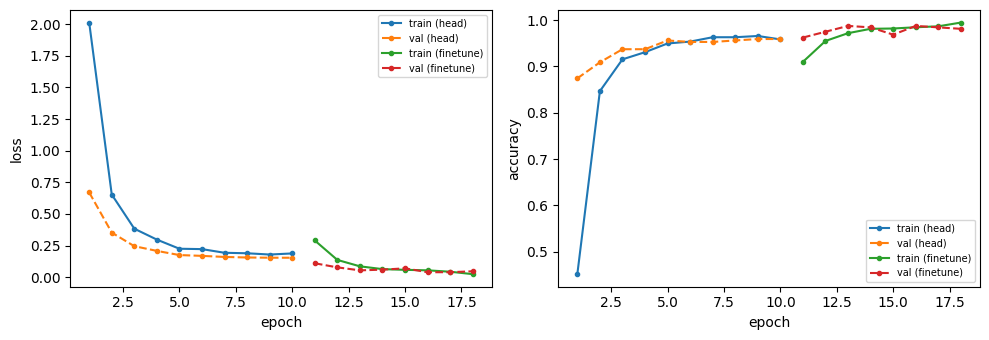

In [9]:
def build_model():
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = layers.Rescaling(1 / 127.5, offset=-1)(inp)            # MobileNetV2 preprocessing, inside the model
    base = keras.applications.MobileNetV2(include_top=False, weights=PRETRAINED, input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
    base.trainable = False
    x = base(x, training=False)
    x = layers.Dropout(0.3)(x)
    return keras.Model(inp, layers.Dense(NUM_CLASSES, activation="softmax")(x), name="mobilenetv2_others"), base

def unfreeze_top(base, prefix):
    base.trainable = True
    start = next(i for i, l in enumerate(base.layers) if l.name.startswith(prefix))
    for i, l in enumerate(base.layers):
        l.trainable = i >= start and not isinstance(l, layers.BatchNormalization)

def compile_model(model, lr, epochs):
    sched = keras.optimizers.schedules.CosineDecay(lr, decay_steps=max(1, epochs * STEPS_PER_EPOCH))
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=sched, weight_decay=WEIGHT_DECAY),
                  loss="categorical_crossentropy", metrics=["accuracy"])

def fit(model, epochs, patience):
    cb = [keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=patience, restore_best_weights=True)]
    return model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=cb, verbose=2).history

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
t0 = time.time()
model, base = build_model()
compile_model(model, LR["head"], EPOCHS["head"])
h1 = fit(model, EPOCHS["head"], EPOCHS["head"])                       # stage 1: head only
best1 = max(h1["val_accuracy"])
stage1_w = OUT_DIR / "models" / "stage1.weights.h5"
model.save_weights(stage1_w)
unfreeze_top(base, UNFREEZE_FROM)
compile_model(model, LR["finetune"], EPOCHS["finetune"])
h2 = fit(model, EPOCHS["finetune"], PATIENCE["finetune"])             # stage 2: fine-tune the top blocks
chosen_stage = "finetune"
if max(h2["val_accuracy"]) < best1:                                    # fine-tuning is worse than stage 1 → back to stage 1
    model.load_weights(stage1_w)
    chosen_stage = "head"
stage1_w.unlink()
train_min = (time.time() - t0) / 60
model_path = OUT_DIR / "models" / "mobilenetv2_others.keras"
model.save(model_path)
print(f"trained in {train_min:.1f} min; stage used = {chosen_stage}; params = {model.count_params():,}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
off = 0
for stage, hh in [("head", h1), ("finetune", h2)]:
    ep = np.arange(off, off + len(hh["loss"])) + 1
    ax[0].plot(ep, hh["loss"], "o-", ms=3, label=f"train ({stage})"); ax[0].plot(ep, hh["val_loss"], "o--", ms=3, label=f"val ({stage})")
    ax[1].plot(ep, hh["accuracy"], "o-", ms=3, label=f"train ({stage})"); ax[1].plot(ep, hh["val_accuracy"], "o--", ms=3, label=f"val ({stage})")
    off += len(hh["loss"])
for a, t in zip(ax, ["loss", "accuracy"]):
    a.set_xlabel("epoch"); a.set_ylabel(t); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT_DIR / "figures" / "training_curves.png", dpi=120); plt.show()

# Task6 - Results on validation only
Saved to `validation_summary.json` before any test evaluation. Rates come with a 95% Wilson interval (as in M1).
- **known accuracy**: on the 20-class images; a prediction of `OTHERS` counts as wrong.
- **false rejection**: share of 20-class images predicted as `OTHERS`.
- **OTHERS recall**: share of OTHERS images predicted as `OTHERS`. **OTHERS precision**: share of `OTHERS` predictions that are OTHERS images.

In [10]:
def acc_ci(acc, n, z=1.96):
    """Wilson 95% CI (as in M1); valid also at 0% and 100%."""
    if n == 0:
        return (float("nan"), float("nan"))
    center = (acc + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * math.sqrt(acc * (1 - acc) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return max(0.0, center - half), min(1.0, center + half)

def predict(ds):
    return model.predict(ds, verbose=0)

def summary(y, prob):
    pred = prob.argmax(1)
    known, oth = y != OTHERS_IDX, y == OTHERS_IDX
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)
    np.add.at(cm, (y, pred), 1)
    tp = np.diag(cm).astype(float)
    with np.errstate(divide="ignore", invalid="ignore"):
        prec = np.nan_to_num(tp / cm.sum(0)); rec = np.nan_to_num(tp / cm.sum(1))
        f1 = np.nan_to_num(2 * prec * rec / (prec + rec))
    def rate(mask, cond):
        k, n_ = int((cond & mask).sum()), int(mask.sum())
        r = k / n_ if n_ else float("nan")
        return dict(value=r, k=k, n=n_, ci=acc_ci(r, n_) if n_ else None)
    out = dict(accuracy_21=rate(np.ones_like(known), pred == y),
               known_accuracy=rate(known, pred == y),
               false_rejection=rate(known, pred == OTHERS_IDX),
               others_recall=rate(oth, pred == OTHERS_IDX),
               others_precision=rate(pred == OTHERS_IDX, oth),
               per_class_f1=f1.tolist(), confusion=cm.tolist())
    return out

def fmt(d):
    v, ci = d["value"], d["ci"]
    return "–" if d["n"] == 0 else f"{v:.4f} ({d['k']}/{d['n']}; CI {ci[0]:.3f}–{ci[1]:.3f})"

y_val = items("val")[1]
p_val = predict(val_ds)
val = summary(y_val, p_val)
val_rows = [[k, fmt(val[k])] for k in ["accuracy_21", "known_accuracy", "false_rejection", "others_recall", "others_precision"]]
display(Markdown(md_table(["validation", "value"], val_rows)))
print(f"M1 20-class MobileNetV2 validation accuracy: {M1_MOBILENET['val_accuracy']}")
(OUT_DIR / "records" / "validation_summary.json").write_text(json.dumps(dict(
    run=RUN_TAG, chosen_stage=chosen_stage, validation={k: v for k, v in val.items() if k not in ("confusion",)},
    decided_at=datetime.now(timezone.utc).isoformat(), test_seen_before=False), indent=2, default=float), encoding="utf-8")

| validation | value |
|---|---|
| accuracy_21 | 0.9874 (314/318; CI 0.968–0.995) |
| known_accuracy | 0.9934 (301/303; CI 0.976–0.998) |
| false_rejection | 0.0000 (0/303; CI 0.000–0.013) |
| others_recall | 0.8667 (13/15; CI 0.621–0.963) |
| others_precision | 1.0000 (13/13; CI 0.772–1.000) |

M1 20-class MobileNetV2 validation accuracy: 0.9967


1312

_(Fill in after running.)_ On validation, the 21-class model reaches known accuracy […] (M1 20-class model: 0.9967), rejects […] of the 20-class images as OTHERS, and recognizes […] of the OTHERS images.

# Task7 - Test
Three test sets: (a) the **303 M1 test images** (20 classes, unchanged), (b) the **OTHERS test photos**, (c) the **unseen-object photos** (kinds never trained on).

In [11]:
y_test, test_rows = items("test")[1], items("test")[2]
p_test = predict(test_ds)
test = summary(y_test, p_test)
rows = [[k, fmt(test[k])] for k in ["accuracy_21", "known_accuracy", "false_rejection", "others_recall", "others_precision"]]
if unseen:
    p_uns = predict(unseen_ds)
    pred_uns = p_uns.argmax(1)
    k = int((pred_uns == OTHERS_IDX).sum())
    unseen_rate = dict(value=k / len(unseen), k=k, n=len(unseen), ci=acc_ci(k / len(unseen), len(unseen)))
    rows.append(["unseen rejected as OTHERS", fmt(unseen_rate)])
    for r, pr, p in zip(unseen, pred_uns, p_uns):
        r.update(pred=CLASSES[int(pr)], prob=round(float(p.max()), 4))
else:
    unseen_rate = None
display(Markdown(md_table(["test", "value"], rows)))
if unseen:
    # Per kind: which unseen kinds are rejected, and which course class the others are mistaken for
    kind_rows = []
    for kd in UNSEEN_KINDS:
        rs = [r for r in unseen if r["kind"] == kd]
        wrong = sorted({r["pred"] for r in rs if r["pred"] != OTHERS_ID})
        kind_rows.append([kd, f"{sum(r['pred'] == OTHERS_ID for r in rs)}/{len(rs)}", ", ".join(wrong) or "–"])
    display(Markdown(md_table(["unseen kind", "rejected as OTHERS", "mistaken for"], kind_rows)))
print(f"M1 20-class MobileNetV2 test accuracy on the same 303 images: {M1_MOBILENET['test_accuracy']}")
with open(OUT_DIR / "records" / "test_run_log.jsonl", "a", encoding="utf-8") as f:
    f.write(json.dumps(dict(time=datetime.now(timezone.utc).isoformat(), model=model_path.name, sets=["test", "unseen"])) + "\n")

| test | value |
|---|---|
| accuracy_21 | 0.9874 (314/318; CI 0.968–0.995) |
| known_accuracy | 0.9967 (302/303; CI 0.982–0.999) |
| false_rejection | 0.0033 (1/303; CI 0.001–0.018) |
| others_recall | 0.8000 (12/15; CI 0.548–0.930) |
| others_precision | 0.9231 (12/13; CI 0.667–0.986) |
| unseen rejected as OTHERS | 0.4167 (15/36; CI 0.271–0.578) |

| unseen kind | rejected as OTHERS | mistaken for |
|---|---|---|
| candle | 1/2 | OBJ222 |
| desk_lamp | 2/2 | – |
| dice | 1/2 | OBJ108 |
| electric_kettle | 0/2 | OBJ001, OBJ011 |
| glove | 1/2 | OBJ777 |
| hat | 0/2 | OBJ001, OBJ666 |
| headphones | 2/2 | – |
| pen | 0/2 | OBJ608, OBJ777 |
| power_outlet | 2/2 | – |
| sock | 2/2 | – |
| stapler | 1/2 | OBJ777 |
| sunglasses | 0/2 | OBJ201 |
| tissue_box | 0/2 | OBJ002, OBJ125 |
| toaster | 1/2 | OBJ001 |
| toothbrush | 2/2 | – |
| towel | 0/2 | OBJ001, OBJ222 |
| toy_car | 0/2 | OBJ007 |
| wallet | 0/2 | OBJ001 |

M1 20-class MobileNetV2 test accuracy on the same 303 images: 0.9934


| class | test F1 |
|---|---|
| OBJ000 | 1.000 |
| OBJ001 | 0.968 |
| OBJ002 | 1.000 |
| OBJ004 | 1.000 |
| OBJ006 | 0.968 |
| OBJ007 | 1.000 |
| OBJ011 | 1.000 |
| OBJ070 | 1.000 |
| OBJ108 | 1.000 |
| OBJ111 | 0.968 |
| OBJ123 | 1.000 |
| OBJ125 | 1.000 |
| OBJ201 | 1.000 |
| OBJ222 | 0.966 |
| OBJ523 | 1.000 |
| OBJ529 | 1.000 |
| OBJ608 | 1.000 |
| OBJ666 | 1.000 |
| OBJ777 | 1.000 |
| OBJ916 | 1.000 |
| OTHERS | 0.857 |

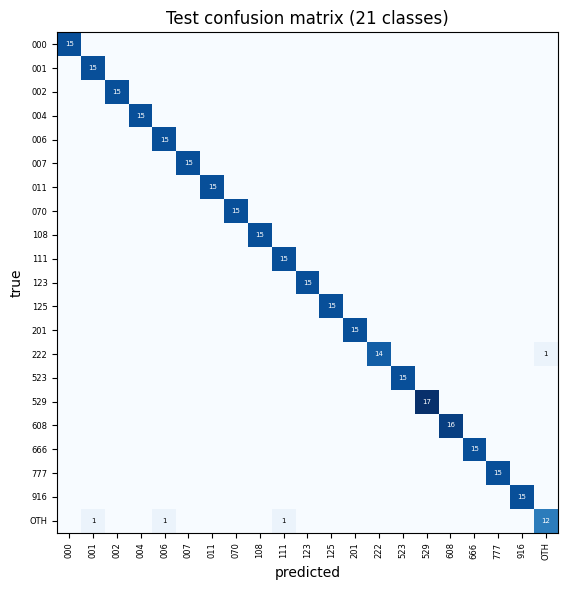

In [12]:
# Per-class F1 on test and the confusion matrix (last row / column = OTHERS)
display(Markdown(md_table(["class", "test F1"], [[CLASSES[k], f"{test['per_class_f1'][k]:.3f}"] for k in range(NUM_CLASSES)])))
cm = np.array(test["confusion"])
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(cm, cmap="Blues")
labels = [CLASSES[k][3:] if k < OTHERS_IDX else "OTH" for k in range(NUM_CLASSES)]
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(labels, rotation=90, fontsize=6)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(labels, fontsize=6)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=5, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Test confusion matrix (21 classes)")
plt.tight_layout(); plt.savefig(OUT_DIR / "figures" / "confusion_matrix.png", dpi=150); plt.show()

25 such errors


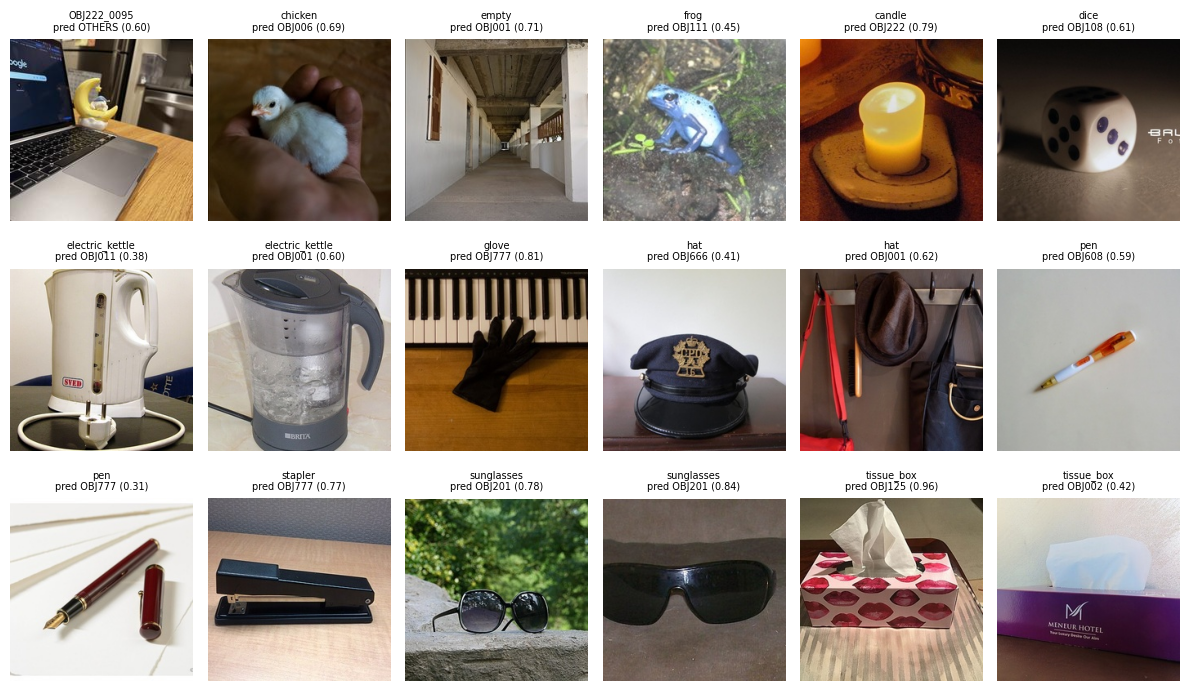

In [13]:
# Errors that matter for "not one of the 20": course images rejected as OTHERS, and OTHERS / unseen photos given a course ID
pred_test = p_test.argmax(1)
err = [(r, CLASSES[int(pr)], float(p.max())) for r, y, pr, p in zip(test_rows, y_test, pred_test, p_test)
       if (y != OTHERS_IDX and pr == OTHERS_IDX) or (y == OTHERS_IDX and pr != OTHERS_IDX)]
err += [(r, r["pred"], r["prob"]) for r in unseen if r["pred"] != OTHERS_ID]
print(f"{len(err)} such errors")
if err:
    k = min(18, len(err))
    plt.figure(figsize=(12, 2.4 * math.ceil(k / 6)))
    for i, (r, pr, pb) in enumerate(err[:k]):
        plt.subplot(math.ceil(k / 6), 6, i + 1)
        with Image.open(r["path"]) as im:
            plt.imshow(im)
        plt.axis("off"); plt.title(f"{r.get('kind', r['image_id'])}\npred {pr} ({pb:.2f})", fontsize=7)
    plt.tight_layout(); plt.savefig(OUT_DIR / "figures" / "others_errors.png", dpi=110); plt.show()

_(Fill in after running.)_ On the 303 M1 test images the 21-class model reaches […] (20-class model: 0.9934) and rejects […] of them as OTHERS. It recognizes […] of the OTHERS test photos and […] of the unseen-object photos. The unseen photos show whether it rejects new kinds of objects or only objects similar to the OTHERS training photos.

- **[…]**

# Task8 - Saved model, class map and run records
The 21-class model has its own class map `classes_with_others.json` (0–19 as in M1, 20 = `OTHERS`).
The 20-class `classes.json`, the M2 detector and the demo's detection mode are not affected.

In [14]:
cw_path = OUT_DIR / "data" / "classes_with_others.json"
cw_path.write_text(json.dumps({str(i): c for i, c in CLASSES.items()}, indent=2), encoding="utf-8")
with open(OUT_DIR / "data" / "others_manifest.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=["image_id", "src_name", "kind", "split", "group_id", "group_size", "md5", "phash"], extrasaction="ignore")
    w.writeheader(); w.writerows(others)
if unseen:
    with open(OUT_DIR / "data" / "unseen_manifest.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=["image_id", "src_name", "kind", "md5", "pred", "prob"], extrasaction="ignore")
        w.writeheader(); w.writerows(unseen)

gpu = [tf.config.experimental.get_device_details(g).get("device_name", "GPU") for g in tf.config.list_physical_devices("GPU")]
strip = lambda d: {k: v for k, v in d.items() if k != "confusion"}
rec = dict(run_id=uuid.uuid4().hex, run_tag=RUN_TAG, task="M1 extension: MobileNetV2 with an OTHERS class", smoke=SMOKE,
           data=dict(m1_run=M1_RUN_DIR.name, classes_json_sha256=CLASSES_SHA, split_manifest_sha256=MANIFEST_SHA,
                     classes_with_others_sha256=file_hash(cw_path), n_course_images=len(records), n_others=len(others),
                     course_images_from="cache zip (md5-checked)" if FROM_CACHE else "shared folder (md5-checked)",
                     others_from=OTHERS_FROM,
                     others_split={s: sum(r["split"] == s for r in others) for s in SPLITS}, n_unseen=len(unseen),
                     others_kinds=OTHERS_KINDS, unseen_kinds=UNSEEN_KINDS),
           config=dict(seed=SEED, img_size=IMG_SIZE, batch=BATCH, epochs=EPOCHS, patience=PATIENCE, lr=LR, weight_decay=WEIGHT_DECAY,
                       unfreeze_from=UNFREEZE_FROM, pretrained=PRETRAINED, others_preprocessing="EXIF upright, central square crop, 224x224 JPEG"),
           chosen_stage=chosen_stage, train_minutes=round(train_min, 2), params=int(model.count_params()),
           validation=strip(val), test=strip(test), unseen=unseen_rate, m1_mobilenetv2=M1_MOBILENET,
           environment=dict(python=platform.python_version(), tensorflow=tf.__version__, keras=keras.__version__, gpu=gpu or ["none"]),
           artifact=dict(path=f"models/{model_path.name}", sha256=file_hash(model_path)), issues=issues)
(OUT_DIR / "records" / "run_mobilenetv2_others.json").write_text(json.dumps(rec, indent=2, default=float), encoding="utf-8")

(OUT_DIR / "M1_others_results.md").write_text(
    f"# M1 extension: MobileNetV2 + OTHERS ({RUN_TAG})\n\n"
    f"OTHERS photos: {len(others)} in {len(OTHERS_KINDS)} kinds (train / val / test = {counts[0]} / {counts[1]} / {counts[2]}); "
    f"unseen-object photos: {len(unseen)} in {len(UNSEEN_KINDS)} kinds.\n\n"
    f"## Validation\n\n{md_table(['metric', 'value'], val_rows)}\n\n## Test\n\n{md_table(['metric', 'value'], rows)}\n\n"
    f"M1 20-class MobileNetV2: validation {M1_MOBILENET['val_accuracy']}, test {M1_MOBILENET['test_accuracy']} (same 303 test images).\n\n"
    f"## Data issues\n\n" + ("\n".join(f"- {s}" for s in issues) or "none") + "\n", encoding="utf-8")
print("All outputs saved to:", OUT_DIR)
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print("  ", p.relative_to(OUT_DIR))
print("\nFor the demo: copy models/mobilenetv2_others.keras and data/classes_with_others.json into the repository's models/ folder.")

All outputs saved to: /content/drive/MyDrive/data/IE7615_project/runs/m1o_20261107_113839
   M1_others_results.md
   data/classes_with_others.json
   data/others_manifest.csv
   data/unseen_manifest.csv
   figures/confusion_matrix.png
   figures/others_errors.png
   figures/others_photos.jpg
   figures/training_curves.png
   figures/unseen_photos.jpg
   models/mobilenetv2_others.keras
   records/run_mobilenetv2_others.json
   records/test_run_log.jsonl
   records/validation_summary.json

For the demo: copy models/mobilenetv2_others.keras and data/classes_with_others.json into the repository's models/ folder.
